# Herzkrankheit-Klassifikation: Logistische Regression vs. Random Forest

Ziel: Vorhersage, ob bei einer Person eine Herzkrankheit vorliegt (`target = 1`) oder nicht (`target = 0`), anhand klinischer Messwerte. Verglichen werden ein gut erklärbares Modell (logistische Regression) und ein komplexeres Ensemble-Modell (Random Forest).

> **Überarbeitung (November 2026):** In der ersten Version erreichte der Random Forest ca. 99 % Accuracy. Ursache war **Data Leakage**: Der Datensatz enthält 723 exakte Duplikate, wodurch fast alle Testfälle (199 von 205) auch im Training vorkamen. Diese Version entfernt die Duplikate, passt die Skalierung nur auf den Trainingsdaten an und ergänzt eine 5-fache Kreuzvalidierung. Details im Abschnitt *Prüfung auf Duplikate* und in den Ergebnissen.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Datensatz liegt im Repo unter data/heart.csv (relativer Pfad, damit das Notebook nach dem Klonen direkt läuft)
DATA_PATH = 'data/heart.csv'

In [2]:
#Übersicht Features
df_features = pd.DataFrame({
    'Abkürzung': ['age','sex','cp_type','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','target'],
    'Begriff': ['Age','Sex','Chest Pain Type','Resting Blood Pressure','Serum Cholesterol','Fasting Blood Sugar','Resting ECG Results','Max Heart Rate Achieved','Exercise-Induced Angina','ST Depression (Oldpeak)','ST Slope','Number of Major Vessels (0-4)','Thalassemia','Heart Disease (1 = ja, 0 = nein)'],
})
display(df_features.style.set_caption("Übersicht Features"))

,Abkürzung,Begriff
0,age,Age
1,sex,Sex
2,cp_type,Chest Pain Type
3,trestbps,Resting Blood Pressure
4,chol,Serum Cholesterol
5,fbs,Fasting Blood Sugar
6,restecg,Resting ECG Results
7,thalach,Max Heart Rate Achieved
8,exang,Exercise-Induced Angina
9,oldpeak,ST Depression (Oldpeak)


In [3]:
#Datensatz einlesen
df = pd.read_csv(DATA_PATH)
#Erste Grundattribute der Daten anzeigen
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [4]:
#Datentransformation und -Bereinigung
df.rename(columns={'cp': 'cp_type'}, inplace=True)
df.isnull().sum() #0 Nullwerte in den Features
# In diesem Fall hatte der gegebene Datensatz schon eine hohe Datenqualität
df.head()

/var/folders/4w/xh7bljyx4rlgy578r5nrc9300000gn/T/ipykernel_7364/2037177257.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={'cp': 'cp_type'}, inplace=True)


,age,sex,cp_type,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


<h2>Prüfung auf Duplikate</h2>

Neben fehlenden Werten müssen auch **doppelte Zeilen** geprüft werden. Bleiben Duplikate im Datensatz, landen identische Patient:innen gleichzeitig im Trainings- und im Testset. Das Modell wird dann an Fällen geprüft, die es bereits kennt, und die gemessene Genauigkeit ist künstlich hoch (**Data Leakage**). Genau das war in der ersten Version dieses Notebooks die Ursache für die ca. 99 % Accuracy des Random Forest.

In [5]:
anzahl_duplikate = df.duplicated().sum()
print(f'Zeilen gesamt: {len(df)}, davon exakte Duplikate: {anzahl_duplikate}')

df = df.drop_duplicates().reset_index(drop=True)
print(f'Eindeutige Datensätze nach Bereinigung: {len(df)}')
print('Verteilung der Zielvariable:')
print(df['target'].value_counts())

Zeilen gesamt: 1025, davon exakte Duplikate: 723
Eindeutige Datensätze nach Bereinigung: 302
Verteilung der Zielvariable:
target
1    164
0    138
Name: count, dtype: int64


Korrelation von age mit Target: -0.22
Korrelation von sex mit Target: -0.28
Korrelation von cp_type mit Target: 0.43
Korrelation von trestbps mit Target: -0.15
Korrelation von chol mit Target: -0.08
Korrelation von fbs mit Target: -0.03
Korrelation von restecg mit Target: 0.13
Korrelation von thalach mit Target: 0.42
Korrelation von exang mit Target: -0.44
Korrelation von oldpeak mit Target: -0.43
Korrelation von slope mit Target: 0.34
Korrelation von ca mit Target: -0.41
Korrelation von thal mit Target: -0.34


<Axes: >

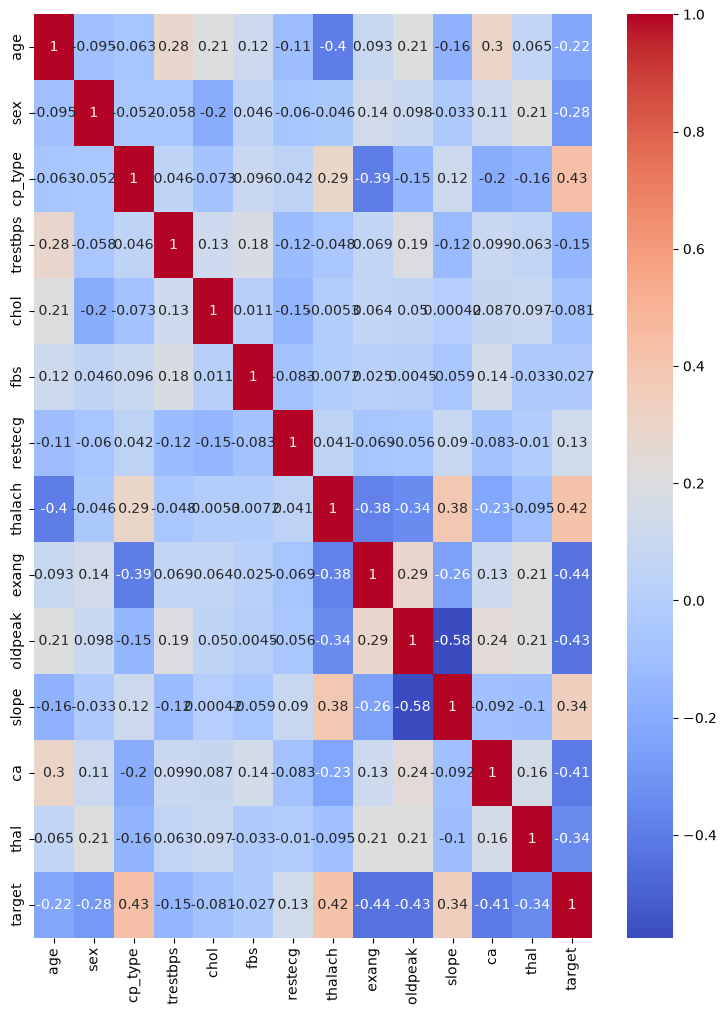

In [6]:
# Ermittlung der Korrelationen von den Features
correlations = {}

for col in df.columns:
    if col != 'target':  # nur Features, nicht das Target selbst
        corr = df[col].corr(df['target'])
        correlations[col] = corr
        print(f"Korrelation von {col} mit Target: {corr:.2f}")

import seaborn as sns
plt.figure(figsize=(9,12))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm')

<h1>Visuelle Analyse der Features mit den höchsten Corr-Werten gegenüber 'target'</h1>

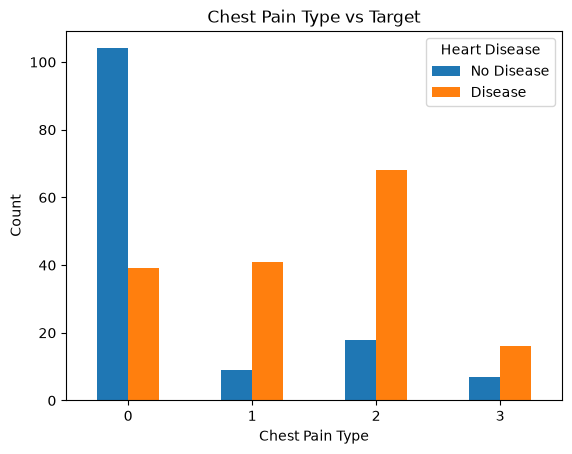

In [7]:
#Feature 1: cp_type vs target (Korrelationswert siehe Ausgabe oben)
cp_counts = df.groupby(['cp_type', 'target']).size().unstack(fill_value=0)

# Plotting
cp_counts.plot(kind='bar')
plt.title('Chest Pain Type vs Target')
plt.xlabel('Chest Pain Type')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Heart Disease', labels=['No Disease', 'Disease'])
plt.show()

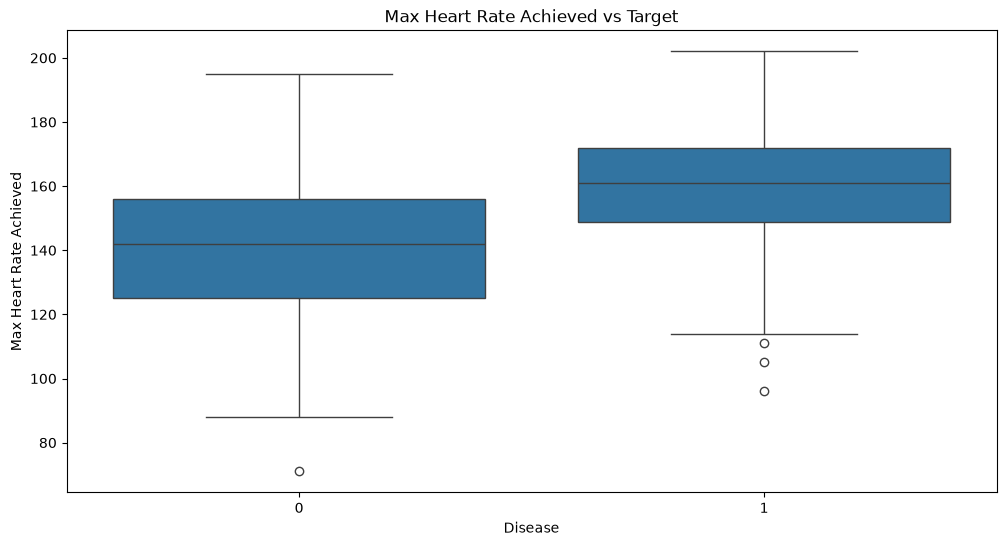

In [8]:
#Feature 2: max heart rate vs target (Korrelationswert siehe Ausgabe oben)
plt.figure(figsize=(12, 6))
sns.boxplot(x='target', y='thalach', data=df)
plt.title('Max Heart Rate Achieved vs Target')
plt.xlabel('Disease')
plt.ylabel('Max Heart Rate Achieved')
plt.show()

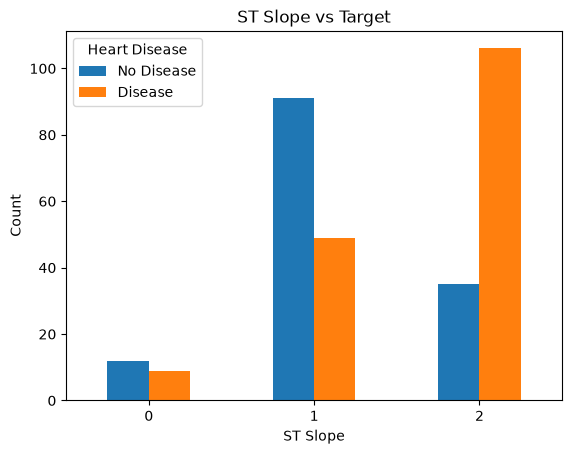

In [9]:
#Feature 3: slope vs target (Korrelationswert siehe Ausgabe oben)
cp_counts = df.groupby(['slope', 'target']).size().unstack(fill_value=0)

# Plotting
cp_counts.plot(kind='bar')
plt.title('ST Slope vs Target')
plt.xlabel('ST Slope')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.legend(title='Heart Disease', labels=['No Disease', 'Disease'])
plt.show()

In [10]:
# Vorverarbeitung und Aufteilung in Trainings- und Testdaten
# Wichtig: Der StandardScaler wird erst innerhalb der Modell-Pipeline und nur auf den Trainingsdaten angepasst.
# So fließen keine Informationen aus dem Testset (z. B. Mittelwert/Streuung) in das Training ein.
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

num_col = ['age','trestbps','chol','thalach','oldpeak']
cat_col_ordinal = ['cp_type', 'restecg', 'slope','ca','thal']
norm = num_col + cat_col_ordinal   # binäre Spalten (sex, fbs, exang) bleiben unverändert

# X für die Merkmale ohne 'target', y nur für 'target'
X = df.drop('target', axis=1)
y = df['target']

# Stratifizierte Aufteilung 80/20: Das Verhältnis krank/gesund bleibt in beiden Sets gleich
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

preprocessing = ColumnTransformer([('scale', StandardScaler(), norm)], remainder='passthrough')
print('Trainingsset:', X_train.shape, '| Testset:', X_test.shape)

Trainingsset: (241, 13) | Testset: (61, 13)


<h2>Analyse mit Hilfe der Logistischen Regressions Funktion:</h2>

Vorhersage Accuracy Score (Testset): 0.803
Report anderer Metriken: 
               precision    recall  f1-score   support

           0       0.81      0.75      0.78        28
           1       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61

Logistische Regression – 5-fache Kreuzvalidierung:
  accuracy : 0.838 ± 0.028
  roc_auc  : 0.906 ± 0.019
  recall   : 0.878 ± 0.109


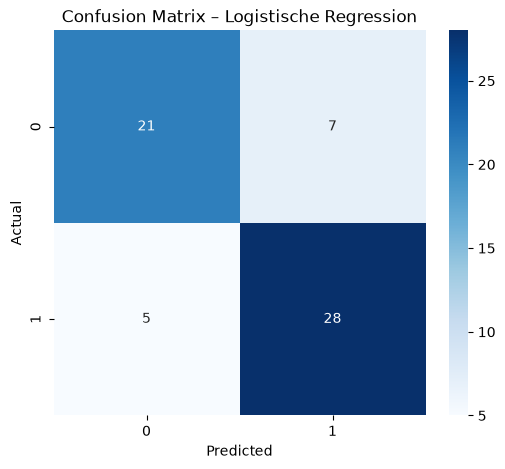

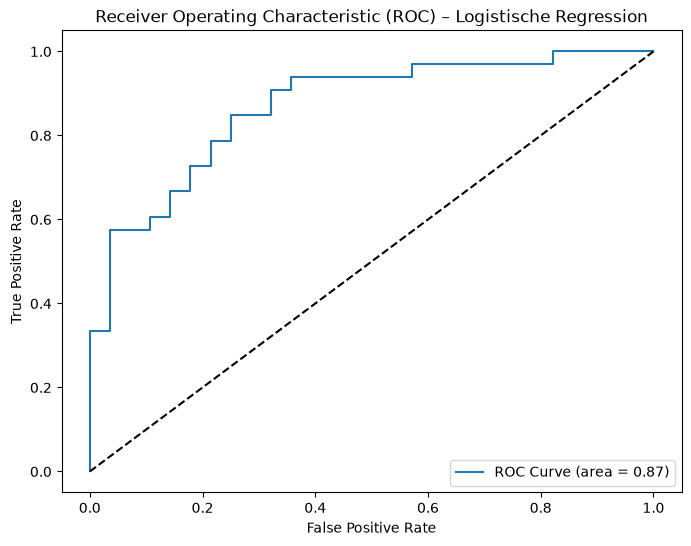

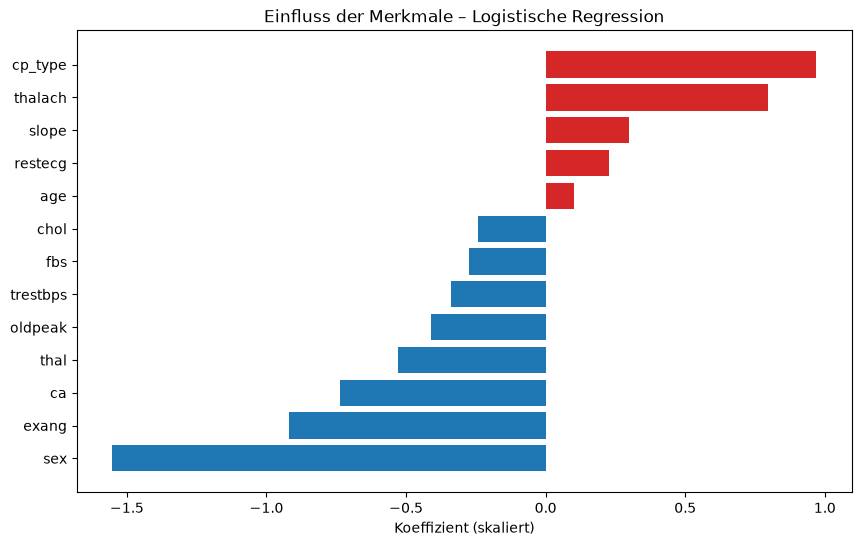

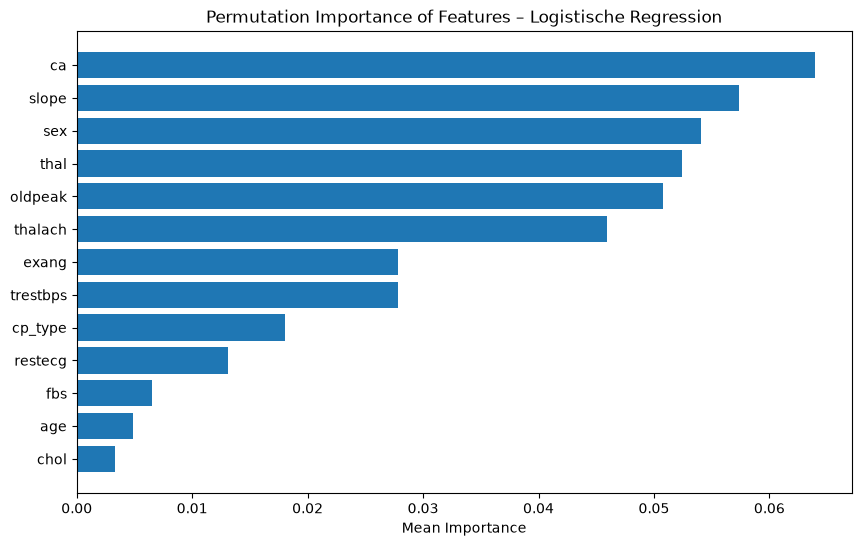

In [11]:
#Für ML Models
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc, classification_report
from sklearn.inspection import permutation_importance

# Bei nur ~300 Datensätzen schwankt das Ergebnis eines einzelnen Testsets stark.
# Deshalb zusätzlich 5-fache Kreuzvalidierung: 5 verschiedene Aufteilungen, Ergebnis = Mittelwert ± Streuung.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def kreuzvalidierung(model, name):
    scores = cross_validate(model, X, y, cv=cv, scoring=['accuracy', 'roc_auc', 'recall'])
    print(f'{name} – 5-fache Kreuzvalidierung:')
    for metrik in ['accuracy', 'roc_auc', 'recall']:
        werte = scores[f'test_{metrik}']
        print(f'  {metrik:9s}: {werte.mean():.3f} ± {werte.std():.3f}')
    return scores

# Initalisierung und Training des Modells (Skalierung + Modell in einer Pipeline)
log_model = make_pipeline(preprocessing, LogisticRegression(max_iter=1000))
log_model.fit(X_train, y_train)

# Vorhersage unter Nutzung des Test-sets
y_pred = log_model.predict(X_test)

# Berechnung der Accuracy (Reihenfolge der Argumente: erst wahre Werte, dann Vorhersage)
print('Vorhersage Accuracy Score (Testset):', round(accuracy_score(y_test, y_pred), 3))
print('Report anderer Metriken: \n', classification_report(y_test, y_pred))
cv_log = kreuzvalidierung(log_model, 'Logistische Regression')

# Erstellung und Visualisierung einer Konfusionsmatrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix – Logistische Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Erstellung einer Receiver Operating Characteristic (ROC) Kurve und des Area under curve(AUC) Wertes
y_prob = log_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) – Logistische Regression')
plt.legend(loc='lower right')
plt.show()

# Koeffizienten: zeigen direkt, in welche Richtung und wie stark ein Merkmal das Risiko verschiebt
# (positiv = erhöht die Wahrscheinlichkeit für target = 1). Skalierte Merkmale sind untereinander vergleichbar;
# bei den binären Merkmalen (sex, fbs, exang) zeigt der Koeffizient den Effekt eines Wechsels von 0 auf 1.
feature_names = [n.split('__')[-1] for n in log_model[0].get_feature_names_out()]
coefs = pd.Series(log_model[-1].coef_[0], index=feature_names).sort_values()
plt.figure(figsize=(10, 6))
plt.barh(coefs.index, coefs.values, color=['tab:blue' if v < 0 else 'tab:red' for v in coefs.values])
plt.xlabel('Koeffizient (skaliert)')
plt.title('Einfluss der Merkmale – Logistische Regression')
plt.show()

# Permutationen visualisieren, um Feature Relevanz zu erforschen
result = permutation_importance(log_model, X_test, y_test, n_repeats=10, random_state=42)
sorted_idx = result.importances_mean.argsort()

plt.figure(figsize=(10, 6))
plt.barh(X.columns[sorted_idx], result.importances_mean[sorted_idx])
plt.xlabel('Mean Importance')
plt.title('Permutation Importance of Features – Logistische Regression')
plt.show()

<h2>Weitere Analyse mit Hilfe der RandomForest Funktion:</h2>

Vorhersage Accuracy Score (Testset): 0.754
Report anderer Metriken für Klassifikation 
               precision    recall  f1-score   support

           0       0.74      0.71      0.73        28
           1       0.76      0.79      0.78        33

    accuracy                           0.75        61
   macro avg       0.75      0.75      0.75        61
weighted avg       0.75      0.75      0.75        61



Random Forest – 5-fache Kreuzvalidierung:
  accuracy : 0.825 ± 0.033
  roc_auc  : 0.907 ± 0.011
  recall   : 0.854 ± 0.073


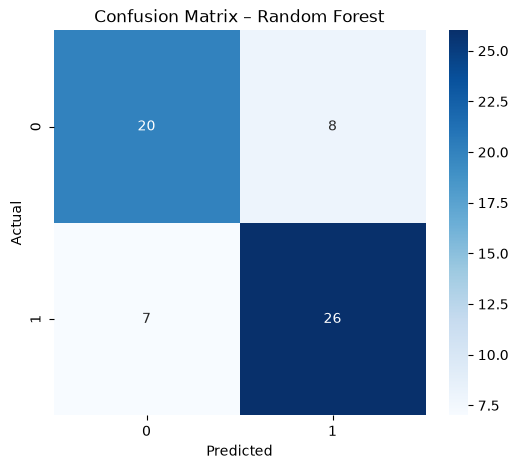

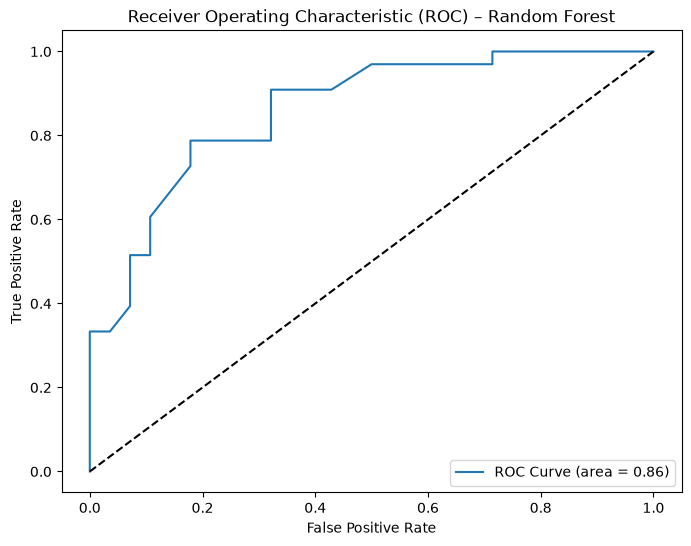

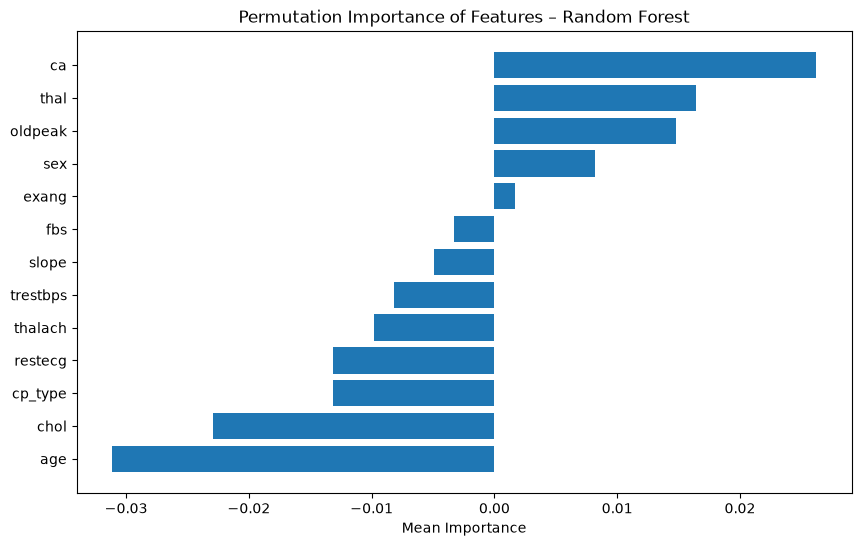

In [12]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest braucht keine Skalierung; gleicher Trainings-/Test-Split wie oben für einen fairen Vergleich
rand = RandomForestClassifier(random_state=42)
rand.fit(X_train, y_train)

pred_rand = rand.predict(X_test)

# Berechnung der Accuracy
print('Vorhersage Accuracy Score (Testset):', round(accuracy_score(y_test, pred_rand), 3))
print('Report anderer Metriken für Klassifikation \n', classification_report(y_test, pred_rand))
cv_rand = kreuzvalidierung(rand, 'Random Forest')

# Konfusionsmatrix
cm = confusion_matrix(y_test, pred_rand)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix – Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC-Kurve: braucht Wahrscheinlichkeiten, nicht die fertigen 0/1-Vorhersagen
y_prob = rand.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) – Random Forest')
plt.legend(loc='lower right')
plt.show()

# Permutationen visualisieren, um Feature Relevanz zu erforschen
result = permutation_importance(rand, X_test, y_test, n_repeats=10, random_state=42)
sorted_idx = result.importances_mean.argsort()

plt.figure(figsize=(10, 6))
plt.barh(X.columns[sorted_idx], result.importances_mean[sorted_idx])
plt.xlabel('Mean Importance')
plt.title('Permutation Importance of Features – Random Forest')
plt.show()

<h2>Modellvergleich (5-fache Kreuzvalidierung)</h2>

In [13]:
vergleich = pd.DataFrame({
    name: {metrik: f"{scores[f'test_{metrik}'].mean():.3f} ± {scores[f'test_{metrik}'].std():.3f}"
           for metrik in ['accuracy', 'roc_auc', 'recall']}
    for name, scores in [('Logistische Regression', cv_log), ('Random Forest', cv_rand)]
}).T
vergleich

,accuracy,roc_auc,recall
Logistische Regression,0.838 ± 0.028,0.906 ± 0.019,0.878 ± 0.109
Random Forest,0.825 ± 0.033,0.907 ± 0.011,0.854 ± 0.073


<h1>Ergebnisse:</h1>

Ziel war es, eine Herzkrankheit mit zwei Algorithmen vorherzusagen, der logistischen Regression und dem Random Forest, und beide hinsichtlich Vorhersageleistung und praktischer Anwendbarkeit zu bewerten. Grundlage sind die **302 eindeutigen Datensätze** nach Entfernen der Duplikate.

| Modell | Accuracy (5-fach CV) | ROC-AUC (5-fach CV) | Recall „krank“ (5-fach CV) |
|---|---|---|---|
| Logistische Regression | 0,84 ± 0,03 | 0,91 ± 0,02 | 0,88 ± 0,11 |
| Random Forest | 0,83 ± 0,03 | 0,91 ± 0,01 | 0,85 ± 0,07 |

*Accuracy = Anteil richtiger Vorhersagen. ROC-AUC = wie gut das Modell Kranke und Gesunde trennt (1,0 = perfekt, 0,5 = Zufall). Recall = Anteil der tatsächlich Kranken, die erkannt werden; im medizinischen Kontext besonders wichtig, weil übersehene Fälle teurer sind als Fehlalarme.*

<h3>Lessons Learned: Data Leakage durch Duplikate</h3>
In der ersten Version erreichte der Random Forest ca. 99 % Accuracy. Ursache: 723 der 1.025 Zeilen waren exakte Duplikate. Dadurch kamen 199 von 205 Testfällen bereits im Training vor, und das Modell wurde an Daten geprüft, die es auswendig kannte. Nach der Bereinigung liegen beide Modelle bei rund 83–84 %. Zusätzlich wird der Scaler jetzt nur auf den Trainingsdaten angepasst, und eine 5-fache Kreuzvalidierung ersetzt die Bewertung über ein einzelnes, kleines Testset (61 Fälle).

<h3>Random Forest</h3>
Vorteil: Kann nichtlineare Zusammenhänge und Wechselwirkungen zwischen Merkmalen abbilden.

Nachteil: Die Entscheidungswege sind schwer nachvollziehbar („Black Box“), und auf diesem Datensatz bringt die höhere Komplexität **keinen messbaren Vorteil**.

<h3>Logistische Regression</h3>
Vorteil: Die Koeffizienten zeigen direkt, welches Merkmal das Risiko in welche Richtung verschiebt. Die Entscheidung ist für Mediziner:innen nachvollziehbar.

Nachteil: Bildet nur lineare Zusammenhänge ab; bei komplexeren Daten kann das ein Nachteil sein.

<h3>Empfehlung:</h3>
Für diesen Anwendungsfall empfiehlt sich die **logistische Regression**. Sie erreicht die gleiche Vorhersageleistung wie der Random Forest und ist zugleich erklärbar. Im medizinischen Umfeld ist das ein entscheidendes Kriterium. Die Unterschiede zwischen beiden Modellen liegen innerhalb der Streuung der Kreuzvalidierung.

<h3>Grenzen und nächste Schritte</h3>

- Mit 302 Datensätzen ist die Datenbasis klein; die Ergebnisse sind als Tendenz zu verstehen.
- **Plausibilitätsprüfung der Zielvariable:** Die Koeffizienten wirken medizinisch teils widersprüchlich. Eine höhere maximale Herzfrequenz (`thalach`) erhöht die Wahrscheinlichkeit für `target = 1`, belastungsinduzierte Angina (`exang`) senkt sie. Das spricht dafür, dass `target = 1` in dieser Kaggle-Version eher „geringeres Risiko“ bedeutet. Vor einem echten Einsatz müsste die Kodierung mit der Originalquelle (UCI Heart Disease) abgeglichen werden. Die Modellvergleiche bleiben davon unberührt.
- Der Entscheidungsschwellenwert (aktuell 0,5) könnte zugunsten eines höheren Recalls gesenkt werden.
- Hyperparameter-Tuning (z. B. Regularisierung, Baumtiefe) und erklärbare KI-Methoden wie SHAP wären sinnvolle Erweiterungen.